# 1. 데이터를 읽기
------------------------
df.shape   : (행개수, 열개수) 를 보여준다
df.columns : 컬럼이름을 보여준다.
df.head    : 앞의 5개 행을 보여준다

In [35]:

import sys
print(sys.executable)
from pathlib import Path
import pandas as pd
#data_path = Path(r"C:\Codyssey26\심화과정\A1-1\data\raw\olist_products_dataset.csv")
data_path = Path(r"C:\Codyssey26\심화과정\A1-1\data\raw\olist_order_items_dataset.csv") #Order 별 제품, 판매자 정보,제품ID, 가격, 수량, 배송비, 배송시간 등
df = pd.read_csv(data_path)
print("행과 열:", df.shape) 
print("\n컬럼 이름:")
print(df.columns.tolist())
print("\n앞의 5개 행:")
print(df.head())

c:\Codyssey26\심화과정\A1-1\.venv\Scripts\python.exe
행과 열: (112650, 7)

컬럼 이름:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

앞의 5개 행:
                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value

head()	데이터가 어떻게 생겼나
info()	크기, 타입, 결측 개수
describe()	값의 분포, 이상치 단서
isna().sum()	컬럼별 결측 현황
duplicated().sum()	중복 데이터 여부

In [36]:
print("###  head : Data 의 5개까지 정보 보여주기 ###")
print(df.head())
print("###  Info :  각 컬럼의 데이터 유형과 비어 있지 않은 값의 개수 ###")
print(df.info())
print("###  Describe :  값의 분포, 이상치 단서 ###")
display(df.describe(include="all").T)
print("###  isna.sum :  컬럼별 결측 현황 ###")
print(df.isna().sum().sort_values(ascending=False))
print("###  duplicated :  중복 행 현황 ###")
print("중복 행 수:", df.duplicated().sum())


###  head : Data 의 5개까지 정보 보여주기 ###
                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  
0  2017-09-19 09:45:35   58.90          13.29  
1  2017-05-03 11:05:13  239.90          19.93  
2  2018-01-18 14:48:30  199.00          17.87  
3  2018-

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,112650,98666,8272b63d03f5f79c56e9e4120aec44ef,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_item_id,112650.0,NaN,NaN,NaN,1.197834,0.705124,1.0,1.0,1.0,1.0,21.0
product_id,112650,32951,aca2eb7d00ea1a7b8ebd4e68314663af,527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_id,112650,3095,6560211a19b47992c3666cc44a7e94c0,2033,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipping_limit_date,112650,93318,2018-03-01 02:50:48,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,112650.0,NaN,NaN,NaN,120.653739,183.633928,0.85,39.9,74.99,134.9,6735.0
freight_value,112650.0,NaN,NaN,NaN,19.99032,15.806405,0.0,13.08,16.26,21.15,409.68


###  isna.sum :  컬럼별 결측 현황 ###
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
###  duplicated :  중복 행 현황 ###
중복 행 수: 0


### IQR 이상치 탐지 함수

`find_iqr_outliers(series, multiplier=1.5)`는 숫자 컬럼(Series) 하나를 받아서 IQR 기준으로 이상치를 찾는 함수이다.

- `q1`, `q3`: 데이터를 작은 것부터 줄 세웠을 때 25%, 75% 지점의 값 (`describe()`의 25%, 75%와 같다)
- `iqr = q3 - q1`: 가운데 50%가 퍼진 폭
- `lower`, `upper`: 하한 = Q1 − 1.5 × IQR, 상한 = Q3 + 1.5 × IQR (`multiplier`로 1.5를 조절할 수 있다)
- `mask`: 하한보다 작거나 상한보다 크면 `True`인 Series (행마다 이상치 여부)
- 반환값: `(mask, lower, upper)` 세 가지

아래 셀은 이 함수를 `price`에 적용한다. `dropna()`로 결측을 뺀 컬럼을 넘긴다.

**결과:** 하한 −102.6, 상한 277.4, 탐지된 이상치 8,427개(전체 112,650행의 약 7.5%). 하한이 음수라서 가격이 낮아서 걸린 값은 없고, 전부 상한을 넘는 고가 구간이다. `mask.sum()`은 이상치 값의 합이 아니라 `True`의 **개수**이다.


In [37]:
def find_iqr_outliers(series, multiplier=1.5):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - multiplier * iqr
    upper = q3 + multiplier * iqr
    mask = (series < lower) | (series > upper)
    return mask, lower, upper

mask, lower, upper = find_iqr_outliers(df["price"].dropna())
print("하한:", lower)
print("상한:", upper)
print("탐지된 이상치 수:", mask.sum())



하한: -102.6
상한: 277.4
탐지된 이상치 수: 8427


### 함수 없이 이상치 행 꺼내기

앞 셀의 함수와 같은 계산을 함수 없이 풀어 쓴 코드이고, 이상치 행 전체를 `outliers`에 저장한다.

- `price = df["price"]`: 가격 컬럼을 Series로 꺼낸다.
- `q1`, `q3`, `iqr`, `lower`, `upper`: 위 함수와 같은 계산이며 배수 1.5가 코드에 고정되어 있다.
- `outlier_mask = price.notna() & (...)`: 결측이 아닌 행 중에서 하한 미만 또는 상한 초과인 행만 `True`. `notna()`는 결측을 이상치로 세지 않겠다는 것을 명시한 방어적 표현이며, 이 데이터는 결측이 0개라 결과가 달라지지 않는다.
- `outliers = df.loc[outlier_mask]`: `True`인 행을 모든 컬럼으로 꺼낸다.
- `print(outliers.head())`: 이상치 행의 **앞 5개**를 출력한다. 가장 비싼 5건이 아니므로 극단값을 보려면 `outliers.nlargest(5, "price")`를 쓴다.


In [38]:
price = df["price"]
q1 = price.quantile(0.25)
q3 = price.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outlier_mask = price.notna() & ((price < lower) | (price > upper))
outliers = df.loc[outlier_mask]
print(outliers.head())



                            order_id  order_item_id  \
7   000576fe39319847cbb9d288c5617fa6              1   
16  0009c9a17f916a706d71784483a5d643              1   
26  0011d82c4b53e22e84023405fb467e57              1   
30  00137e170939bba5a3134e2386413108              1   
39  0017afd5076e074a48f1f1a4c7bac9c5              1   

                          product_id                         seller_id  \
7   557d850972a7d6f792fd18ae1400d9b6  5996cddab893a4652a15592fb58ab8db   
16  3f27ac8e699df3d300ec4a5d8c5cf0b2  fcb5ace8bcc92f75707dc0f01a27d269   
26  c389f712c4b4510bc997cee93e8b1a28  bfd27a966d91cfaafdb25d076585f0da   
30  672e757f331900b9deea127a2a7b79fd  e59aa562b9f8076dd550fcddf0e73491   
39  fe59a1e006df3ac42bf0ceb876d70969  25c5c91f63607446a97b143d2d535d31   

    shipping_limit_date  price  freight_value  
7   2018-07-10 12:30:45  810.0          70.75  
16  2018-05-02 09:31:53  639.0          11.34  
26  2018-01-29 21:51:25  289.0          26.33  
30  2017-11-30 06:30:55  397.0  

### 이상치 처리 전/후 가격 통계 비교

이상치를 제외하기 전과 후의 `price` 통계를 한 표로 비교한다.

- `before`: 전체 가격 (112,650개)
- `after`: 이상치를 뺀 가격 (`~outlier_mask`로 이상치가 아닌 행만 선택, 104,223개). 원본 `df`에서 행을 삭제한 것이 아니라 비교용으로만 따로 만든 값이다.
- `describe()` 결과를 두 열로 나란히 놓고, `skew`(왜도, 한쪽으로 치우친 정도)와 `변화량 = 처리 후 − 처리 전`을 추가한다.

**관찰:** 평균은 120.65에서 83.97로, 표준편차는 183.63에서 58.58로 크게 줄었지만 중앙값(50%)은 74.99에서 69.00으로 조금만 변했다. 최댓값은 6735에서 277.30으로, 왜도는 7.92에서 1.01로 낮아졌다.

**시사점:** 평균과 표준편차는 소수의 고가 상품(이상치)에 크게 좌우되고 중앙값은 영향이 작다. 이상치를 삭제하면 분포가 훨씬 덜 치우치지만, 정상적인 고가 상품 7.5%가 함께 사라지므로 분석 목적에 따라 삭제 여부를 정해야 한다.


In [40]:
before = df["price"]
after = df.loc[~outlier_mask, "price"]          # 삭제 방식

compare = pd.DataFrame({
    "처리 전": before.describe(),
    "처리 후": after.describe(),
})
compare.loc["skew"] = [before.skew(), after.skew()]   # 치우침 정도
compare["변화량"] = compare["처리 후"] - compare["처리 전"]
print(compare.round(2))

            처리 전       처리 후      변화량
count  112650.00  104223.00 -8427.00
mean      120.65      83.97   -36.68
std       183.63      58.58  -125.05
min         0.85       0.85     0.00
25%        39.90      38.50    -1.40
50%        74.99      69.00    -5.99
75%       134.90     118.99   -15.91
max      6735.00     277.30 -6457.70
skew        7.92       1.01    -6.91


### 처리 전/후 시각화 (상자그림 + 히스토그램)

앞 셀의 `before`, `after`를 그림으로 비교한다.

- **왼쪽 상자그림:** `Before`와 `After`를 나란히 그린다. 상자는 25%~75%, 안의 선은 중앙값, 점은 이상치이다.
- **오른쪽 히스토그램:** 가격을 50칸으로 나눠 두 분포를 반투명(`alpha=0.5`)으로 겹쳐 그린다.
- `tick_labels=[...]`: 상자그림 아래 이름표. matplotlib 3.9 이후 버전에서는 예전 `labels` 인자가 없어졌고 `tick_labels`를 써야 한다.

**관찰:** Before는 6735까지 이어지는 이상치 점 때문에 그래프가 한쪽으로 찌그러져 상자가 거의 안 보이고, After는 상자와 분포 모양이 뚜렷하게 보인다.


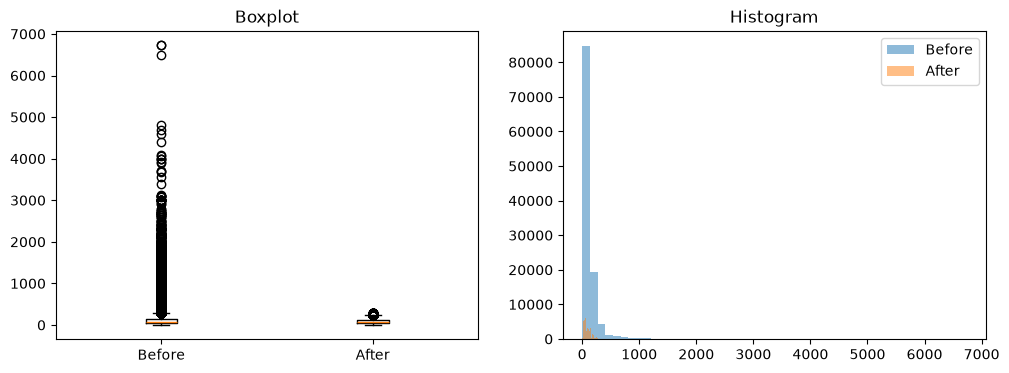

In [41]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].boxplot([before, after], tick_labels=["Before", "After"])
ax[0].set_title("Boxplot")
ax[1].hist(before, bins=50, alpha=0.5, label="Before")
ax[1].hist(after, bins=50, alpha=0.5, label="After")
ax[1].set_title("Histogram"); ax[1].legend()
plt.show()

# 2. 박스플롯 — 이상치 확인

price(가격)의 분포와 이상치를 한 장으로 보여 주는 그래프입니다. 앞에서 IQR로 계산한 내용이 그림으로 나온 것입니다.

### 그림 읽는 법

| 그림 요소 | 의미 | 이 데이터의 값 |
|---|---|---|
| 상자 | Q1(25%) ~ Q3(75%), 가운데 50%의 데이터 | 약 39.9 ~ 134.9 |
| 상자 안의 선 | 중앙값(50%) | 약 74.99 |
| 수염(상자 양옆 선) | 정상 범위의 끝 (Q3 + 1.5 × IQR) | 오른쪽 끝 약 277.4 |
| 동그라미(○) | 수염 밖의 값 = 이상치 | 277.4 초과 |

### 관찰한 내용

1. **가격 대부분이 낮은 구간에 몰려 있다.** 상자가 가로축 0 부근에 얇게 붙어 있다. 가운데 50%가 약 39.9 ~ 134.9 사이라서 전체 범위(0.85 ~ 6735)에 비해 매우 좁다.
2. **오른쪽으로 길게 치우친 분포다.** 277.4 오른쪽으로 이상치 점이 6500 이상까지 이어진다. 왜도(skew)는 7.92이고, 평균(120.65)이 중앙값(74.99)보다 큰 것도 이 꼬리 때문이다.
3. **이상치가 많다.** 277.4를 넘는 행이 8,427개로 전체 112,650행의 약 7.5%다. 점이 겹쳐서 굵은 선처럼 보인다. 정규분포라면 약 0.7%만 걸리는 것과 비교하면 10배 이상이다.
4. **극단적으로 멀리 떨어진 값이 있다.** 4000 이상, 특히 약 6500과 최댓값 6735 부근에 점이 드문드문 있다.

### 시사점

대부분의 상품은 저가이고 소수의 고가 상품이 평균과 표준편차를 크게 끌어올린다. 따라서 가격의 대표값은 평균(120.65)보다 중앙값(74.99)이 적절하다. 277.4를 넘는 값이 모두 오류는 아니고 실제 고가 상품일 수 있으므로, 이상치를 일괄 삭제하기 전에 건수와 비율을 먼저 확인하고 처리 기준을 정한다.

### 그래프의 한계

이 그림은 이상치가 많다는 점은 잘 보여 주지만, 상자가 너무 얇아서 정상 범위 안의 분포(중앙값, 사분위수)는 읽기 어렵다. 세부를 보려면 `plt.xlim(0, 500)`으로 범위를 좁히거나 `plt.xscale("log")`로 로그 눈금을 사용한다.


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x="price")
plt.title("Price Outlier Check")
plt.xlabel("Price")
plt.tight_layout()
plt.show()


### 상품명 대신 카테고리명 단어 수·글자 수 파생 변수 만들기

과제의 "텍스트에서 단어 수 또는 문자열 길이를 계산해 새 변수를 만든다"에 해당하는 코드이다.

**상품명이 없어 대체했다.** `order_items`에는 상품명(`product_name`)이 없고, 상품 정보 파일(`olist_products_dataset.csv`)에도 상품명 글자는 없다. 대신 아래 두 가지를 사용한다.
- `product_name_lenght`: 상품명의 글자 수 (이미 계산되어 있는 값) → `name_length`
- `product_category_name`: 카테고리명 텍스트를 영어로 번역한 뒤 단어 수를 계산 → `name_word_count`

**코드의 흐름**
1. `products`와 번역표(`trans`)를 읽고 `merge`로 영어 카테고리명(`product_category_name_english`)을 붙인다. `how="left"`라서 `products`의 행은 모두 유지된다.
2. 영어 카테고리명의 `_`를 공백으로 바꿔 단어 수를 센다. 카테고리가 비어 있으면 0이다.
3. `set_index("product_id")`로 상품 ID를 이름표로 만들고 `map`으로 `df`의 각 행 `product_id`에 해당하는 값을 찾아 새 컬럼 3개를 붙인다. 엑셀의 VLOOKUP과 같은 방식이며, 여러 번 실행해도 컬럼이 중복되지 않는다.

**확인할 것:** 행 수는 112,650으로 그대로여야 한다. 예상 범위는 `name_word_count` 0~6, `name_length` 5~76이며 `name_length`에는 결측이 1,603행 있다(상품 정보가 비어 있는 상품). 가격과의 상관계수는 각각 약 0.030, 0.017로 거의 0이다.


In [ ]:
# Olist 데이터에는 상품명(product_name) 텍스트가 없으므로
# 카테고리명(영문 번역)의 단어 수와 상품명 글자 수(product_name_lenght)로 대체한다.
raw_dir = Path(r"C:\Codyssey26\심화과정\A1-1\data\raw")
products = pd.read_csv(raw_dir / "olist_products_dataset.csv")
trans = pd.read_csv(raw_dir / "product_category_name_translation.csv", encoding="utf-8-sig")
products = products.merge(trans, on="product_category_name", how="left")

# 방법 A: 카테고리명의 단어 수 (언더스코어를 공백으로 바꿔서 센다, 카테고리가 없으면 0)
products["name_word_count"] = (
    products["product_category_name_english"]
    .fillna("").str.replace("_", " ").str.split().str.len()
)

# df(order_items)의 행 수는 그대로 두고 product_id 기준으로 컬럼만 붙인다
by_product = products.set_index("product_id")
df["product_category_name_english"] = df["product_id"].map(by_product["product_category_name_english"])
df["name_word_count"] = df["product_id"].map(by_product["name_word_count"])
df["name_length"] = df["product_id"].map(by_product["product_name_lenght"])   # 방법 B: 상품명 글자 수

print("행 수:", len(df))
print(df[["product_id", "product_category_name_english", "name_word_count", "name_length"]].head())
print(df[["name_word_count", "name_length"]].describe())


### 카테고리명이 비어 있는 상품 확인 (products 테이블)

`products`에서 `product_category_name`이 비어 있는 행만 골라 보여 준다.

- `products["product_category_name"].isna()`: 비어 있으면 `True`인 Series
- `products[...]`: `True`인 행만 선택 (이렇게 조건으로 행을 고르는 방식을 불리언 마스크라고 한다)
- `len(missing_rows)`: 해당 행의 개수
- `to_string()`: 출력이 `...`로 생략되지 않게 전체를 문자열로 바꿔 출력한다

앞의 셀에서 `df`가 아니라 `products`를 쓰는 이유는 카테고리 컬럼이 `order_items`가 아니라 `products` 테이블에 있기 때문이다. 결과는 바로 아래 메모에 정리했다.


In [ ]:
missing_rows = products[products["product_category_name"].isna()]

print("결측치 행 수:", len(missing_rows))
print("결측치 행:")
print(missing_rows.to_string())
display(missing_rows.to_string())

categrory name 이 없는 행수는 610 개 이며, 전체 행 32,951 개 중에 약 1.85 % 이다

### 중복 행 확인 (products 전체 컬럼 기준)

`products.duplicated().sum()`은 **모든 컬럼 값이 같은 행**의 개수를 센다.

- `duplicated()`는 같은 행이 여러 번 나올 때 첫 번째는 `False`, 두 번째부터 `True`로 표시한다.
- `sum()`은 `True`의 개수를 더한 것이므로 "첫 번째를 제외한 중복 행 수"이다.
- 0이면 완전히 같은 행이 하나도 없다는 뜻이다.


In [ ]:
print("중복 행 수:", products.duplicated().sum())

### products 전체 출력

`products` 전체를 출력해서 구조를 눈으로 확인하는 셀이다.

- 행이 32,951개이고 컬럼이 많아서 pandas가 중간을 `...`로 생략해 보여 준다. 생략되지 않은 전체가 필요하면 `to_string()`을 쓰거나 `pd.set_option("display.max_rows", None)`으로 옵션을 바꾼다.
- 앞에서 만든 영어 카테고리명(`product_category_name_english`)과 `name_word_count` 컬럼이 `products`에 붙어 있는지 확인할 수 있다.


In [ ]:
print("\n전체 행:")
print(products)

중복행 수 는 0건이다 

### product_id 기준 중복 확인

`products.duplicated(subset="product_id", keep=False)`은 **`product_id`만 같으면** 중복으로 보고 해당 행을 모두 보여 준다.

- `subset="product_id"`: 이 컬럼만 비교한다(전체 컬럼이 아니다).
- `keep=False`: 중복된 행을 첫 번째까지 포함해 **전부** 표시한다.
- 상품 ID는 상품마다 하나여야 하므로 0이 정상이다. 앞의 `df["product_id"].map(...)`이 상품마다 값 하나만 찾으려면 이 컬럼이 중복되지 않아야 하는데, 0건이어서 안전하다.


In [ ]:
dup_rows = products[products.duplicated(subset="product_id", keep=False)]

print("product_id 중복 행 수:", len(dup_rows))
print(dup_rows.to_string())